# 🏴‍☠️ The Treasure of Tensor Island — ✅ SOLUTIONS
### Build your own Tensor Renormalization Group — and beat Onsager

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dartsushi/TNR_tutorial/blob/main/TNR_treasure_hunt_solutions.ipynb)

Ahoy! Somewhere in the Tensor Seas lies a vault. Its lock opens only for those who can compute the
**free energy of the 2D Ising model** in the thermodynamic limit — to five digits or better —
with an algorithm **they wrote themselves**.

You know tensor networks. You have never written a TRG. By the end of this map you will have:

1. **derived** the tensor network for the 2D Ising partition function,
2. **written** the Levin–Nave Tensor Renormalization Group (TRG) from scratch, and
3. **computed** the free energy of a lattice with $2^{30} \approx 10^9$ spins and compared it with
   Onsager's exact solution.

Then we show you where the real treasure is buried. 🦜

## 🗺️ The map (solutions edition)

This notebook contains a complete, working solution for every island of `TNR_treasure_hunt.ipynb`.
The code is a **line-by-line port of [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl)** (v0.7) to numpy:
every function says which TNRKit source it mirrors, so after the session you can open the package and
recognise every line.

| Island | Exercise function | TNRKit.jl counterpart |
|---|---|---|
| 🏝️ 1 | `ising_tensor` | `classical_ising(Trivial, β)` — `src/models/ising.jl` |
| 🌊 2 | `split_tensor` | `SVD12` — `src/utility/projectors.jl` |
| 🏰 3 | `trg_step` | `step!(::TRG, trunc)` — `src/schemes/trg.jl` |
| 🌋 4 | `trg_free_energy` | `run!` + `finalize!` + `free_energy` — `src/schemes/tnrscheme.jl`, `src/utility/finalize.jl`, `src/utility/free_energy.jl` |

---
## ⚓ 0 · The Harbour

Run the toolbox below. It gives you:

| name | what it is |
|---|---|
| `beta_c` | critical inverse temperature $\beta_c = \tfrac12\ln(1+\sqrt2) \approx 0.4407$ |
| `f_exact(beta)` | Onsager's exact free energy per site |
| `lnZ_bruteforce(beta, L)` | $\ln Z$ of an $L\times L$ torus by brute-force enumeration |
| `checkpoint_island1(...)` … | the checkpoints |
| `open_treasure_chest(...)` | the final test |

In [2]:
# ⚓ THE HARBOUR MASTER'S TOOLBOX
# Run this cell once. You do not need to read it — but no pirate will stop you.
# Everything here is pre-installed on Google Colab (numpy, scipy, matplotlib).

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.special import ellipk

beta_c = 0.5 * np.log(1 + np.sqrt(2))  # critical inverse temperature ≈ 0.4406867935
TREASURE_BETAS = [0.3, 0.4, beta_c, 0.5, 0.6]  # the β's that guard the vault


# ---------- exact results (Onsager 1944, Yang 1952) ----------
def f_exact(beta):
    """Onsager's exact free energy per site of the 2D Ising model (J = 1, h = 0)."""
    k = 1 / np.sinh(2 * beta) ** 2
    integrand = lambda th: np.log(np.cosh(2 * beta) ** 2 + np.sqrt(1 + k**2 - 2 * k * np.cos(2 * th)) / k)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        val, _ = quad(integrand, 0, np.pi, epsabs=1e-13, epsrel=1e-13, limit=500)
    return -(np.log(2) / 2 + val / (2 * np.pi)) / beta


def u_exact(beta):
    """Exact internal energy per site, u = d(βf)/dβ (diverging slope at β_c)."""
    t = np.tanh(2 * beta)
    k = 2 * np.sinh(2 * beta) / np.cosh(2 * beta) ** 2
    return -(1 / t) * (1 + (2 / np.pi) * (2 * t**2 - 1) * ellipk(k**2))


# ---------- brute force and exact contraction on tiny tori ----------
def lnZ_bruteforce(beta, L):
    """ln Z of an L x L periodic Ising lattice by summing all 2^(L*L) configurations."""
    n = L * L
    spins = 1 - 2 * ((np.arange(2**n)[:, None] >> np.arange(n)) & 1)
    s = spins.reshape(-1, L, L)
    E = (s * np.roll(s, 1, axis=1)).sum((1, 2)) + (s * np.roll(s, 1, axis=2)).sum((1, 2))
    x = beta * E
    return x.max() + np.log(np.exp(x - x.max()).sum())


def lnZ_tensor_torus(T, L):
    """ln Z of an L x L torus built from copies of T[l, d, u, r], contracted exactly."""
    T = np.asarray(T, dtype=float)
    D = T.shape[0]
    R = T
    for _ in range(L - 1):  # a ring of L tensors -> row transfer matrix
        n = R.shape[1]
        R = np.einsum("adub,bevc->adeuvc", R, T).reshape(D, n * D, n * D, D)
    TM = np.einsum("adua->du", R)
    return np.log(np.trace(np.linalg.matrix_power(TM, L)))


# ---------- pretty printing ----------
def _ok(msg):
    print("✅ " + msg)


def _fail(msg):
    print("❌ " + msg)
    return False


def _todo(name):
    print(f"🚧 `{name}` still returns None — fill it in first, matey!")
    return False


# ---------- checkpoints ----------
def checkpoint_island1(boltzmann_weight, bond_factor, ising_tensor):
    beta = 0.4
    W, M, T = boltzmann_weight(beta), bond_factor(beta), ising_tensor(beta)
    for name, x in (("boltzmann_weight", W), ("bond_factor", M), ("ising_tensor", T)):
        if x is None:
            return _todo(name)
    W, M, T = np.asarray(W), np.asarray(M), np.asarray(T)
    s = np.array([1, -1])
    if W.shape != (2, 2) or not np.allclose(W, np.exp(beta * np.outer(s, s))):
        return _fail("boltzmann_weight is off. Remember: index 0 <-> spin +1, index 1 <-> spin -1.")
    _ok("Boltzmann weight W is correct.")
    if M.shape != (2, 2) or not np.allclose(M @ M.T, W):
        return _fail("bond_factor: M @ M.T does not reproduce W.")
    _ok("M @ M.T == W. The bond is split in two halves.")
    if T.shape != (2, 2, 2, 2):
        return _fail(f"ising_tensor should have shape (2, 2, 2, 2), got {T.shape}.")
    for b in (0.3, beta_c, 0.6):
        Tb = np.asarray(ising_tensor(b))
        for L in (2, 3, 4):
            mine, exact = lnZ_tensor_torus(Tb, L), lnZ_bruteforce(b, L)
            if not np.isclose(mine, exact, rtol=1e-10, atol=1e-10):
                return _fail(
                    f"On a {L}x{L} torus at β = {b:.4f}: ln Z(tensor) = {mine:.10f}, "
                    f"but brute force gives {exact:.10f}."
                )
    _ok("ln Z on 2x2, 3x3 and 4x4 tori matches brute-force enumeration (65 536 configurations!).")
    print("\n🏝️  ISING ISLE CONQUERED. Sail on to the Singular Strait!")
    return True


def checkpoint_island2(split_tensor):
    rng = np.random.default_rng(7)
    X = rng.standard_normal((3, 4, 5, 2))
    A, B = split_tensor(X, 100)
    if A is None or B is None:
        return _todo("split_tensor")
    A, B = np.asarray(A), np.asarray(B)
    if A.ndim != 3 or B.ndim != 3:
        return _fail(f"A and B should both have 3 legs, got shapes {A.shape} and {B.shape}.")
    if A.shape[:2] != (3, 4) or B.shape[1:] != (5, 2) or A.shape[2] != B.shape[0]:
        return _fail(f"Expected A[i, j, a] and B[a, k, l]; got shapes {A.shape} and {B.shape}.")
    if not np.allclose(np.einsum("ija,akl->ijkl", A, B), X):
        return _fail("Without truncation, A·B should reproduce T exactly.")
    _ok("No truncation: A·B reproduces T exactly.")
    A, B = split_tensor(X, 3)
    A, B = np.asarray(A), np.asarray(B)
    if A.shape != (3, 4, 3) or B.shape != (3, 5, 2):
        return _fail(f"With chi = 3 expected shapes (3, 4, 3) and (3, 5, 2); got {A.shape} and {B.shape}.")
    s = np.linalg.svd(X.reshape(12, 10), compute_uv=False)
    err = np.linalg.norm(np.einsum("ija,akl->ijkl", A, B) - X)
    if not np.isclose(err, np.sqrt(np.sum(s[3:] ** 2))):
        return _fail("Truncated split is not optimal — did you keep the LARGEST singular values?")
    _ok("Truncation keeps the χ largest singular values (optimal, by Eckart–Young).")
    nA, nB = np.linalg.norm(A), np.linalg.norm(B)
    if not np.isclose(nA, nB, rtol=1e-8):
        print("⚠️  Works, but A and B have different norms. Splitting √S to both sides keeps things balanced.")
    print("\n🌊  SINGULAR STRAIT CROSSED. The castle is in sight!")
    return True


def _test_tensor():
    # a deliberately ugly, non-symmetric tensor: it catches swapped legs
    return np.fromfunction(lambda l, d, u, r: np.cos(1 + l + 2 * d + 3 * u + 5 * r) + 0.3 * l * r + 0.1 * d, (2, 2, 2, 2))


def checkpoint_island3(trg_step):
    T = _test_tensor()
    Tn = trg_step(T, 4)
    if Tn is None:
        return _todo("trg_step")
    Tn = np.asarray(Tn)
    if Tn.ndim != 4:
        return _fail(f"The new tensor should have 4 legs, got shape {Tn.shape}.")
    two_sites = np.einsum("abcd,dcba->", T, T)
    if not np.isclose(np.einsum("abba->", Tn), two_sites):
        return _fail(
            "A 1x1 torus of the NEW tensor should equal a 2-site torus of the OLD tensor "
            f"({two_sites:.8f}), got {np.einsum('abba->', Tn):.8f}. Check which legs you glue together."
        )
    _ok("Exact identity: Tr(T_new) on a 1x1 torus == 2-site torus of T.")
    h = np.einsum("abbc,cdda->", Tn, Tn)
    v = np.einsum("abca,dcbd->", Tn, Tn)
    if not (np.isclose(h, 26.519232143495525) and np.isclose(v, 25.181410635798148)):
        return _fail(
            "The 2x1 and 1x2 tori of the new tensor are wrong: probably the legs of T_new are in the "
            "wrong order. Output order must be (l, d, u, r) of the rotated lattice."
        )
    _ok("Leg order of the new tensor (l, d, u, r) is correct.")
    Tb = trg_step(trg_step(np.ones((2, 2, 2, 2)) + _test_tensor(), 3), 3)
    if np.asarray(Tb).shape != (3, 3, 3, 3):
        return _fail(f"With chi = 3, the new tensor should be (3, 3, 3, 3), got {np.asarray(Tb).shape}.")
    _ok("Truncation to χ works: bond dimension stays bounded.")
    print("\n🏰  COARSE-GRAIN CASTLE TAKEN. Only the mountain remains between you and the vault!")
    return True


def checkpoint_island4(trg_free_energy):
    beta = 0.35
    f = trg_free_energy(beta, 8, 20)
    if f is None:
        return _todo("trg_free_energy")
    fe = f_exact(beta)
    rel = abs(f - fe) / abs(fe)
    print(f"   β = {beta}, χ = 8, 20 steps:  f_TRG = {f:.10f}   f_exact = {fe:.10f}   rel. error = {rel:.2e}")
    if rel > 1e-4:
        _diagnose(f, fe, beta)
        return False
    _ok("Free energy within 1e-4 of Onsager.")
    print("\n🌋  MOUNT FREE ENERGY CLIMBED. The vault awaits...")
    return True


def _diagnose(f, fe, beta):
    d = (f - fe) * beta
    if abs(d + np.log(2)) < 1e-2 or abs(d - np.log(2)) < 1e-2:
        _fail("You are off by exactly ln(2)/β: a factor 2 per site too many (or too few) in your tensor/normalisation.")
    elif abs(f / fe - 2) < 0.05 or abs(f / fe - 0.5) < 0.05:
        _fail("You are off by a factor 2: check the weights 1/2^k (does the initial norm get weight 1?).")
    else:
        _fail("Not accurate enough yet. Check your normalisation and the sum ln Z / N = Σ_k ln(n_k) / 2^k.")


CHEST = r"""
            __________
           /\____;;___\        ARRR! THE VAULT OPENS!
          | /         /
          `. ())oo() .         Ye wrote yer own tensor, yer own TRG,
           |\(%()*^^()^\       and beat Onsager to {digits} digits.
          %| |-%-------|
         % \ | %  ))   |       The treasure inside? Turn to the last page
         %  \|%________|       of the map: 'The real treasure'.
"""


def open_treasure_chest(trg_free_energy, chi=16, n_steps=30):
    print(f"Testing your TRG at χ = {chi}, {n_steps} RG steps (a lattice of 2^{n_steps} ≈ {2**n_steps:.1e} spins)\n")
    print(f"{'β':>8} {'T = 1/β':>8} {'f_TRG':>16} {'f_exact':>16} {'rel. error':>11} {'time':>7}")
    worst, ok = 0.0, True
    for beta in TREASURE_BETAS:
        t0 = time.time()
        f = trg_free_energy(beta, chi, n_steps)
        if f is None:
            return _todo("trg_free_energy")
        dt = time.time() - t0
        fe = f_exact(beta)
        rel = abs(f - fe) / abs(fe)
        worst = max(worst, rel)
        flag = "✅" if rel < 1e-5 else "❌"
        ok &= rel < 1e-5
        tag = "  <- β_c" if np.isclose(beta, beta_c) else ""
        print(f"{beta:8.5f} {1/beta:8.4f} {f:16.12f} {fe:16.12f} {rel:11.2e} {dt:6.2f}s {flag}{tag}")
    if ok:
        print(CHEST.format(digits=int(-np.log10(worst))))
    else:
        print("\n🔒 The vault stays shut: every β needs a relative error below 1e-5.")
        print("   Tip: is your χ really 16? Do you normalise every step?")
    return ok


print("⚓ Toolbox loaded. β_c =", beta_c)

⚓ Toolbox loaded. β_c = 0.44068679350977147


### 🧭 Conventions — write these on your hand

**The model.** Classical Ising spins $\sigma_i = \pm 1$ on a square lattice, nearest-neighbour coupling $J=1$, no field:

$$Z(\beta) = \sum_{\{\sigma\}} \prod_{\langle ij\rangle} e^{\beta\,\sigma_i\sigma_j},
\qquad f = -\frac{1}{\beta}\lim_{N\to\infty}\frac{\ln Z}{N}.$$

**Indices.** In code, spin $+1 \leftrightarrow$ index `0` and spin $-1 \leftrightarrow$ index `1`.

**Leg order.** Every 4-leg tensor in this notebook is stored as `T[l, d, u, r]` = **left, down, up, right**:

```text
            u (2)
            |
   l (0) ---T--- r (3)
            |
            d (1)
```

This is exactly the convention of **TNRKit.jl** (there written as a map $V_l\otimes V_d \leftarrow V_u\otimes V_r$),
so everything you build today plugs straight into the package. Neighbouring tensors are glued
`r` ↔ `l` (horizontally) and `u` ↔ `d` (vertically).

---
## 🏝️ 1 · Ising Isle — derive the tensor

The natives of Ising Isle speak only in Boltzmann weights. Our job: rewrite

$$Z = \sum_{\{\sigma\}} \prod_{\langle ij\rangle} W_{\sigma_i\sigma_j}, \qquad W_{\sigma\sigma'} = e^{\beta\sigma\sigma'},$$

as a **tensor network**: one tensor $T$ on every site, contracted over the bonds,
$Z = \mathrm{tTr}\,\bigotimes_{x} T^{(x)}$.

**The recipe.** The weight $W$ lives on a *bond* and couples *two* spins. A tensor lives on a *site*.
So we cut every bond in half, and give one half to each end:

```text
   σ_i ───── W ───── σ_j      =      σ_i ── M ──(a)── Mᵀ ── σ_j          W = M Mᵀ
```

Now every site $i$ carries its spin $\sigma_i$ and **four** half-bonds (left, down, up, right).
Summing over the spin $\sigma_i$ leaves a tensor with four bond legs:

$$T_{ldur} \;=\; \sum_{\sigma=\pm1} M_{\sigma l}\,M_{\sigma d}\,M_{\sigma u}\,M_{\sigma r}.$$

### ▸ Your tasks
1. `boltzmann_weight(beta)`: the $2\times2$ matrix $W$.
2. `bond_factor(beta)`: any $2\times2$ matrix $M$ with $M M^{T} = W$.
3. `ising_tensor(beta)`: the site tensor `T[l, d, u, r]`.

<details><summary>🧭 Hint 1 — the weight matrix</summary>

With index 0 = spin up and index 1 = spin down:
$W = \begin{pmatrix} e^{\beta} & e^{-\beta} \\ e^{-\beta} & e^{\beta}\end{pmatrix}$.
`np.outer(s, s)` with `s = np.array([1, -1])` gives you all products $\sigma\sigma'$ at once.
</details>

<details><summary>🧭 Hint 2 — splitting the bond</summary>

$W$ is real symmetric, so $W = U\Lambda U^T$ and $M = U\sqrt{\Lambda}$ works (`np.linalg.eigh`).
Explicitly, the eigenvalues are $2\cosh\beta$ and $2\sinh\beta$ with eigenvectors $(1,\pm1)/\sqrt2$, giving

$M = \begin{pmatrix} \sqrt{\cosh\beta} & \sqrt{\sinh\beta} \\ \sqrt{\cosh\beta} & -\sqrt{\sinh\beta}\end{pmatrix}.$

(Any other $M' = M O$ with $O$ orthogonal is equally valid — that is a *gauge freedom* of the network.)
</details>

<details><summary>🧭 Hint 3 — gluing the four halves</summary>

`np.einsum` is your best friend. The formula above translates letter by letter:
```python
T = np.einsum('sl,sd,su,sr->ldur', M, M, M, M)
```
</details>

In [3]:
def boltzmann_weight(beta):
    """W[s, s'] = exp(beta * σ σ'), with index 0 <-> σ = +1 and index 1 <-> σ = -1."""
    s = np.array([1, -1])
    return np.exp(beta * np.outer(s, s))


def bond_factor(beta):
    """Any 2x2 matrix M with M @ M.T == W.

    W = U Λ Uᵀ with Λ = diag(2cosh β, 2sinh β) and U = [[1, 1], [1, -1]]/√2, so M = U √Λ.
    """
    c, s = np.sqrt(np.cosh(beta)), np.sqrt(np.sinh(beta))
    return np.array([[c, s], [c, -s]])


def ising_tensor(beta):
    """The Ising site tensor T[l, d, u, r] = Σ_σ M[σ,l] M[σ,d] M[σ,u] M[σ,r]."""
    M = bond_factor(beta)
    return np.einsum("sl,sd,su,sr->ldur", M, M, M, M)

🏁 **Checkpoint 1**

In [4]:
checkpoint_island1(boltzmann_weight, bond_factor, ising_tensor)

✅ Boltzmann weight W is correct.
✅ M @ M.T == W. The bond is split in two halves.
✅ ln Z on 2x2, 3x3 and 4x4 tori matches brute-force enumeration (65 536 configurations!).

🏝️  ISING ISLE CONQUERED. Sail on to the Singular Strait!


True

#### 🦜 The parrot's riddle — answer
With the $M$ above, index 0 of a bond carries $\sqrt{\cosh\beta}$ and index 1 carries $\pm\sqrt{\sinh\beta}$, with the sign equal to $\sigma$. Hence

$$T_{ldur} = (\sqrt{\cosh\beta})^{\#0}\,(\sqrt{\sinh\beta})^{\#1}\sum_{\sigma=\pm1}\sigma^{\,l+d+u+r}
= 2\,(\sqrt{\cosh\beta})^{4-n}(\sqrt{\sinh\beta})^{n}\;\delta_{n\ \mathrm{even}},\qquad n=l+d+u+r .$$

The sum over $\sigma$ kills every entry with an odd number of 1's: the global $\mathbb{Z}_2$ spin-flip symmetry
becomes a **local parity rule** on the tensor. This is precisely the tensor TNRKit.jl builds in
`classical_ising(Trivial, β)` — `2 * parity * bond_tensor⁴` — and `classical_ising(Z2Irrep, β)` stores only the
non-zero symmetry blocks. The cell below checks that they agree **exactly**.

In [5]:
# TNRKit.jl, src/models/ising.jl — `classical_ising(::Type{Trivial}, β)`, ported to numpy:
#
#   init[i,j,k,l] = mod(i+j+k+l, 2) == 0 ? cosh(hβ) : sinh(hβ)          (h = 0: a parity delta)
#   bond_tensor   = diag(√cosh β, √sinh β)
#   @tensor T[-1 -2; -3 -4] := 2 * init[1 2; 3 4] * bx[-1; 1] * by[-2; 2] * by[3; -3] * bx[4; -4]
def classical_ising_tnrkit(beta):
    parity = np.fromfunction(lambda i, j, k, l: (i + j + k + l) % 2 == 0, (2, 2, 2, 2)).astype(float)
    B = np.diag([np.sqrt(np.cosh(beta)), np.sqrt(np.sinh(beta))])
    return 2 * np.einsum("ijkl,ai,bj,kc,ld->abcd", parity, B, B, B, B)


T = ising_tensor(0.4)
print("non-zero entries:", np.count_nonzero(np.abs(T) > 1e-14), "of", T.size)
print("|T_mine - T_TNRKit| =", np.linalg.norm(T - classical_ising_tnrkit(0.4)))

non-zero entries: 8 of 16
|T_mine - T_TNRKit| = 0.0


---
## 🌊 2 · The Singular Strait — cutting a tensor in two

TRG's basic move is to **cut a 4-leg tensor into two 3-leg tensors** along a diagonal, and to throw away
everything but the $\chi$ most important channels in between:

```text
            k                                 k
            |                                 |
     i -----X----- l       ≈              ----B----- l
            |                            /
            j                       (a) /   ← at most χ values
                                       /
                            i -----A---
                                   |
                                   j
```

Group the legs $(i,j)$ into a row index and $(k,l)$ into a column index, take a (truncated) SVD
$X \approx U S V^\dagger$, and absorb $\sqrt{S}$ on both sides:

$$X_{ijkl} \approx \sum_{a=1}^{\chi} A_{ija}\,B_{akl},\qquad A = U\sqrt{S},\quad B=\sqrt{S}\,V^\dagger .$$

By the Eckart–Young theorem this is the **best** rank-$\chi$ approximation in the Frobenius norm.

### ▸ Your task
`split_tensor(T, chi)` → `(A, B)` with `A[i, j, a]` and `B[a, k, l]`, keeping at most `chi` singular values.

<details><summary>🧭 Hint 1</summary>

`T.reshape(D0*D1, D2*D3)` turns the tensor into a matrix; `np.linalg.svd(..., full_matrices=False)` returns `U, S, Vh`
with `S` sorted from large to small.
</details>

<details><summary>🧭 Hint 2</summary>

```python
D = T.shape
U, S, Vh = np.linalg.svd(T.reshape(D[0] * D[1], D[2] * D[3]), full_matrices=False)
k = min(chi, len(S))
sq = np.sqrt(S[:k])
A = (U[:, :k] * sq).reshape(D[0], D[1], k)
B = (sq[:, None] * Vh[:k, :]).reshape(k, D[2], D[3])
```
</details>

In [6]:
# TNRKit.jl, src/utility/projectors.jl:
#
#   function SVD12(T::AbstractTensorMap{E, S, 2, 2}, trunc)
#       U, s, V, e = svd_trunc(T; trunc = trunc)
#       return U * sqrt(s), sqrt(s) * V
#   end
#
# In TensorKit the (i, j) | (k, l) grouping is built into the type (codomain ← domain); in numpy we reshape.
def split_tensor(T, chi):
    """Split T[i, j, k, l] ≈ Σ_a A[i, j, a] B[a, k, l], keeping at most chi singular values."""
    D = T.shape
    U, S, Vh = np.linalg.svd(T.reshape(D[0] * D[1], D[2] * D[3]), full_matrices=False)
    k = min(chi, len(S))  # truncrank(chi)
    sq = np.sqrt(S[:k])
    A = (U[:, :k] * sq).reshape(D[0], D[1], k)
    B = (sq[:, None] * Vh[:k, :]).reshape(k, D[2], D[3])
    return A, B

🏁 **Checkpoint 2**

In [7]:
checkpoint_island2(split_tensor)

✅ No truncation: A·B reproduces T exactly.
✅ Truncation keeps the χ largest singular values (optimal, by Eckart–Young).

🌊  SINGULAR STRAIT CROSSED. The castle is in sight!


True

---
## 🏰 3 · Coarse-Grain Castle — one TRG step

Levin & Nave (PRL **99**, 120601, 2007). Colour the lattice like a checkerboard and cut **every** tensor in
two — but along *different* diagonals on the two sublattices:

```text
   sublattice A: cut (l,d) | (u,r)              sublattice B: cut (d,r) | (l,u)

          u                   u                          u                u
          |                   |                          |                |
     l ---T--- r   ≈          S2--- r               l ---T--- r  ≈   l ---S4
          |                  /                           |                  \
          d             (a) /                            d               (b) \
                    l ---S1                                                   S3--- r
                         |                                                    |
                         d                                                    d

   S1, S2 = split_tensor(T, χ)                     S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), χ)
   S1[l, d, a]   S2[a, u, r]                       S3[d, r, b]   S4[b, l, u]
```

Now look at one **plaquette** (the square between four sites). The four pieces pointing *into* it are:
the upper-right piece of the bottom-left site, the upper-left piece of the bottom-right site, and so on:

```text
                (b')                       (a')
                    \                     /
                     S3 ------ m ------ S1               TL site (B) gives S3 [d=i, r=m, b']
                     |                   |               TR site (A) gives S1 [l=m, d=k, a']
                     i                   k               BL site (A) gives S2 [a, u=i, r=j]
                     |                   |               BR site (B) gives S4 [b, l=j, u=k]
                     S2 ------ j ------ S4
                    /                     \
                 (a)                       (b)
```

Contract the inner square (legs $i, j, k, m$). What is left is a new 4-leg tensor whose legs
$a, b, a', b'$ point **diagonally**: the new lattice is rotated by 45° and has **half** as many sites.
Rotate your head by 45° clockwise and read off the new leg order:

$$T'_{\,l\,d\,u\,r} = T'_{\,a\,b\,b'\,a'} = \sum_{ijkm} S2_{a i j}\; S4_{b j k}\; S1_{m k a'}\; S3_{i m b'} .$$

Each new bond has dimension at most $\chi$. Cost: $\mathcal{O}(\chi^6)$.

### ▸ Your task
`trg_step(T, chi)` → the coarse-grained tensor `T_new[l, d, u, r]`.

<details><summary>🧭 Hint 1 — the second cut</summary>

`T.transpose(1, 3, 0, 2)` reorders the legs to `(d, r, l, u)`, so `split_tensor` cuts it into
`S3[d, r, b]` and `S4[b, l, u]` — exactly the B-sublattice cut.
</details>

<details><summary>🧭 Hint 2 — the contraction</summary>

Translate the formula above directly into an `np.einsum` with 4 input tensors and output `'abwz'`
(where `w` = $b'$, `z` = $a'$). Use `optimize=True` so numpy contracts pairwise and stays at $\chi^6$.
</details>

<details><summary>🧭 Hint 3 — (almost) the answer</summary>

```python
S1, S2 = split_tensor(T, chi)
S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), chi)
T_new = np.einsum('aij,bjk,mkz,imw->abwz', S2, S4, S1, S3, optimize=True)
```
</details>

In [8]:
# TNRKit.jl, src/schemes/trg.jl:
#
#   function step!(scheme::TRG, trunc)
#       A, B = SVD12(scheme.T, trunc)                       # A[l d; α]   B[α; u r]
#       Tp = transpose(scheme.T, ((2, 4), (1, 3)))          # legs (d, r) ← (l, u)
#       C, D = SVD12(Tp, trunc)                             # C[d r; β]   D[β; l u]
#       @plansor scheme.T[-1 -2; -3 -4] := D[-2; 1 2] * B[-1; 4 1] * C[4 3; -3] * A[3 2; -4]
#   end
#
# Dictionary:  A = S1,  B = S2,  C = S3,  D = S4,  and TensorKit's contraction labels
#              1 -> j, 2 -> k, 3 -> m, 4 -> i,  -1 -> a, -2 -> b, -3 -> b', -4 -> a'.
def trg_step(T, chi):
    """One Levin–Nave TRG step: T[l, d, u, r] -> T_new[l, d, u, r] on the 45°-rotated lattice."""
    S1, S2 = split_tensor(T, chi)                         # S1[l, d, a]   S2[a, u, r]
    S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), chi)   # S3[d, r, b]   S4[b, l, u]
    return np.einsum("aij,bjk,mkz,imw->abwz", S2, S4, S1, S3, optimize=True)

🏁 **Checkpoint 3**

In [9]:
checkpoint_island3(trg_step)

✅ Exact identity: Tr(T_new) on a 1x1 torus == 2-site torus of T.
✅ Leg order of the new tensor (l, d, u, r) is correct.
✅ Truncation to χ works: bond dimension stays bounded.

🏰  COARSE-GRAIN CASTLE TAKEN. Only the mountain remains between you and the vault!


True

#### 🦜 How does the checkpoint know you're right?
Without truncation, TRG is *exact*. Glue the new tensor to itself (a $1\times1$ torus, `np.einsum('abba->', T_new)`)
and you get back a tiny lattice of **two** old sites: `np.einsum('abcd,dcba->', T, T)`.
For the Ising tensor that is $\sum_{\sigma_1\sigma_2} e^{4\beta\sigma_1\sigma_2} = 4\cosh 4\beta$. Try it!

In [10]:
beta = 0.4
T = ising_tensor(beta)
print(np.einsum("abba->", trg_step(T, 4)), np.einsum("abcd,dcba->", T, T), 4 * np.cosh(4 * beta))

10.309857884779541 10.309857884779538 10.309857884779541


---
## 🌋 4 · Mount Free Energy — climbing the RG flow

Repeat the TRG step $K$ times and a lattice of $N = 2^K$ sites collapses into a **single tensor**.
But where did the physics go? Into the **normalisation factors**.

The entries of $T$ grow like $e^{(\text{\# sites})\,\cdot\,\text{something}}$ — after a dozen steps they overflow.
So after every step we divide by a number $n_k$ and remember it. With $T_0$ the Ising tensor:

$$
Z_N = \mathrm{tTr}\big[T_0^{\otimes N}\big]
    = n_0^{N}\,\mathrm{tTr}\big[(T_0/n_0)^{\otimes N}\big]
    \approx n_0^{N}\,n_1^{N/2}\,\mathrm{tTr}\big[(T_1/n_1)^{\otimes N/2}\big] = \dots
$$

$$
\Longrightarrow\qquad \frac{\ln Z_N}{N} = \sum_{k=0}^{K} \frac{\ln n_k}{2^k} \;+\; \frac{\ln \mathrm{Tr}\,(\text{last tensor})}{N},
\qquad f = -\frac{1}{\beta}\,\frac{\ln Z_N}{N}.
$$

**Smart choice (the one TNRKit makes):** take $n_k = $ the $1\times1$ torus of $T_k$,
$n_k = \sum_{ab} (T_k)_{abba}$ = `np.einsum('abba->', T)`.
Then the last tensor has trace 1 and the leftover term vanishes: you directly get the free energy of a
$2^K$-site torus, which for $K = 30$ is the thermodynamic limit for all practical purposes.

```text
     k = 0 : normalise T0 -> n_0         weight 1
     k = 1 : step, normalise -> n_1      weight 1/2
     k = 2 : step, normalise -> n_2      weight 1/4
     ...
     k = K : step, normalise -> n_K      weight 1/2^K
```

### ▸ Your task
`trg_free_energy(beta, chi, n_steps)` → the free energy per site $f$ after `n_steps` TRG steps.

<details><summary>🧭 Hint 1</summary>

You need a loop over `k = 0, ..., n_steps`, a running sum `lnz`, and `T = ising_tensor(beta)` as a start.
Normalise *before* the first step too (that is $n_0$, with weight $1/2^0 = 1$).
</details>

<details><summary>🧭 Hint 2 — (almost) the answer</summary>

```python
T = ising_tensor(beta)
lnz = 0.0
for k in range(n_steps + 1):
    if k > 0:
        T = trg_step(T, chi)
    n = np.einsum('abba->', T)
    T = T / n
    lnz += np.log(n) / 2**k
return -lnz / beta
```
</details>

In [11]:
# The TNRKit.jl workflow is split into three pieces; we port each one.
#
# 1) src/utility/finalize.jl — normalise by the 1x1 torus and hand back the norm:
#        function finalize!(scheme::TRG)
#            n = norm(@tensor scheme.T[1 2; 2 1])
#            scheme.T /= n
#            return n
#        end
def finalize(T):
    n = abs(np.einsum("abba->", T))
    return T / n, n


# 2) src/schemes/tnrscheme.jl — run!(scheme, trunc, maxiter(n)) with finalize_beginning = true:
#        push!(data, finalizer.f!(scheme))
#        while crit;  step!(scheme, trunc);  push!(data, finalizer.f!(scheme));  end
def run_trg(T, chi, n_steps):
    T, n = finalize(T)
    data = [n]
    for _ in range(n_steps):
        T = trg_step(T, chi)
        T, n = finalize(T)
        data.append(n)
    return data


# 3) src/utility/free_energy.jl:
#        function free_energy(data, β; scalefactor = 2.0, initial_size = 1.0)
#            lnz = 0.0
#            x = 1.0 - log(initial_size) / log(scalefactor)
#            for (i, z) in enumerate(data)
#                lnz += log(z) * scalefactor^(x - i)
#            end
#            return -lnz / β
#        end
def free_energy(data, beta, scalefactor=2.0, initial_size=1.0):
    x = 1.0 - np.log(initial_size) / np.log(scalefactor)
    lnz = sum(np.log(z) * scalefactor ** (x - i) for i, z in enumerate(data, start=1))
    return -lnz / beta


def trg_free_energy(beta, chi, n_steps=30):
    """Free energy per site of the 2D Ising model from n_steps TRG steps at bond dimension chi."""
    return free_energy(run_trg(ising_tensor(beta), chi, n_steps), beta)

🏁 **Checkpoint 4**

In [12]:
checkpoint_island4(trg_free_energy)

   β = 0.35, χ = 8, 20 steps:  f_TRG = -2.3714328162   f_exact = -2.3714822353   rel. error = 2.08e-05
✅ Free energy within 1e-4 of Onsager.

🌋  MOUNT FREE ENERGY CLIMBED. The vault awaits...


True

#### 🦜 Think about it — answers
* Without normalisation the entries grow like $e^{N_k\cdot\text{const}}$ with $N_k = 2^k$: after 9 steps they are
  $\sim 10^{200}$ and at step 10 they overflow to `inf` (see the cell below).
* $\ln Z$ is *extensive*: every coarse-grained tensor stands for $2^k$ original sites, so the norm $n_k$ we pull out of each
  tensor is pulled out $N/2^k$ times. The **shape** of $T_k$ (its normalised entries) is all that is passed on —
  and that is where correlations, CFT data, ... live. We'll get to those in the treasure chest. 🦜

In [13]:
T = ising_tensor(beta_c)
for k in range(1, 16):
    T = trg_step(T, 8)
    print(f"step {k:2d}: max |T| = {np.abs(T).max():.3e}")
    if not np.isfinite(T).all():
        print("💥 overflow — the ship sank.")
        break

step  1: max |T| = 6.000e+00
step  2: max |T| = 3.714e+01
step  3: max |T| = 1.516e+03
step  4: max |T| = 2.515e+06
step  5: max |T| = 7.116e+12
step  6: max |T| = 5.790e+25
step  7: max |T| = 3.912e+51
step  8: max |T| = 1.819e+103
step  9: max |T| = 4.010e+206
step 10: max |T| = inf
💥 overflow — the ship sank.


---
## 💰 5 · The Vault

The vault is guarded by five temperatures — three in the disordered phase, the critical point, and two in the
ordered phase. The lock opens if your TRG reproduces Onsager's free energy to a **relative error below
$10^{-5}$** at all five, with $\chi = 16$ and 30 RG steps (a lattice of $2^{30}\approx 10^{9}$ spins).

Run the cell. It takes ~10 s.

In [14]:
open_treasure_chest(trg_free_energy)

Testing your TRG at χ = 16, 30 RG steps (a lattice of 2^30 ≈ 1.1e+09 spins)

       β  T = 1/β            f_TRG          f_exact  rel. error    time
 0.30000   3.3333  -2.635196879337  -2.635196903171    9.04e-09   1.50s ✅
 0.40000   2.5000  -2.198407650796  -2.198409551937    8.65e-07   1.41s ✅
 0.44069   2.2692  -2.109641375532  -2.109651144608    4.63e-06   1.51s ✅  <- β_c
 0.50000   2.0000  -2.051584396138  -2.051585625390    5.99e-07   1.39s ✅
 0.60000   1.6667  -2.016887279622  -2.016887313814    1.70e-08   1.42s ✅

            __________
           /\____;;___\        ARRR! THE VAULT OPENS!
          | /         /
          `. ())oo() .         Ye wrote yer own tensor, yer own TRG,
           |\(%()*^^()^\       and beat Onsager to 5 digits.
          %| |-%-------|
         % \ | %  ))   |       The treasure inside? Turn to the last page
         %  \|%________|       of the map: 'The real treasure'.



np.True_

---
## 🐚 6 · Bonus Bay — for the fast sailors

Pick any. Each one is short and reveals real physics.

**(a) How good is χ?** Plot the relative error at $\beta_c$ versus $\chi \in \{4, 6, 8, 12, 16, 24\}$ on a log scale, and
time each run. Does the error decay exponentially or as a power law? How does the runtime scale?

**(b) Where does it hurt?** Plot the relative error versus $\beta \in [0.3, 0.6]$ for $\chi = 8$ and $16$.
Where is TRG worst, and why there?

**(c) Specific heat.** The internal energy is $u = \partial(\beta f)/\partial\beta$ and the specific heat
$c = -\beta^2\,\partial u/\partial\beta$. Compute both by finite differences of your $\beta f(\beta)$ on a grid,
compare $u$ with `u_exact`, and watch $c$ develop its logarithmic peak at $\beta_c$.

<details><summary>🧭 Hint for (c)</summary>

Evaluate `bf = [b * trg_free_energy(b, 12, 30) for b in betas]` on `betas = np.linspace(0.3, 0.6, 31)`,
then `u = np.gradient(bf, betas)` and `c = -betas**2 * np.gradient(u, betas)`. Avoid putting a grid point
*exactly* at $\beta_c$ when you call `u_exact` (it is $0\cdot\infty$ there).
</details>

#### (a) How good is χ?

χ =  4: rel. error = 2.89e-04   (0.01 s)
χ =  6: rel. error = 9.67e-05   (0.02 s)
χ =  8: rel. error = 6.91e-05   (0.15 s)
χ = 12: rel. error = 1.33e-05   (0.63 s)
χ = 16: rel. error = 4.63e-06   (1.54 s)
χ = 24: rel. error = 1.11e-06   (7.13 s)


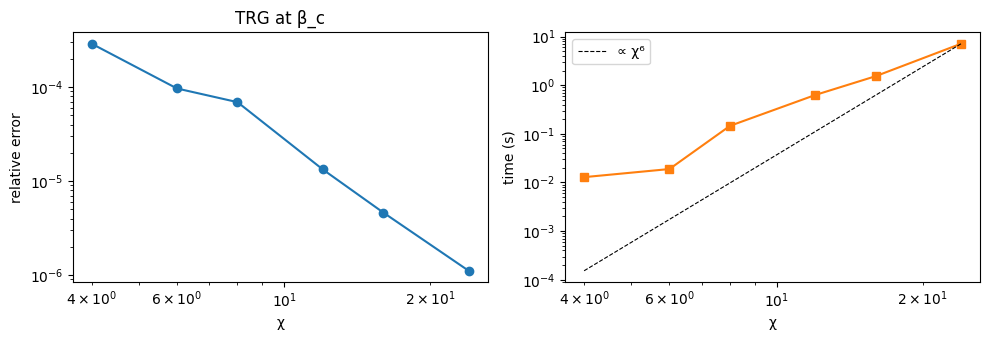

In [15]:
chis = [4, 6, 8, 12, 16, 24]
errs, times = [], []
for chi in chis:
    t0 = time.time()
    f = trg_free_energy(beta_c, chi, 30)
    times.append(time.time() - t0)
    errs.append(abs(f - f_exact(beta_c)) / abs(f_exact(beta_c)))
    print(f"χ = {chi:2d}: rel. error = {errs[-1]:.2e}   ({times[-1]:.2f} s)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(chis, errs, "o-")
ax[0].set(xlabel="χ", ylabel="relative error", title="TRG at β_c")
ax[1].loglog(chis, times, "s-", color="C1")
ax[1].loglog(chis, times[-1] * (np.array(chis) / chis[-1]) ** 6, "k--", lw=0.8, label="∝ χ⁶")
ax[1].set(xlabel="χ", ylabel="time (s)")
ax[1].legend()
plt.tight_layout()
plt.show()

At criticality the error decays roughly as a **power law** in χ (straight line on log–log): there is no gap, the
entanglement of the fixed point grows without bound, and a finite χ always truncates something. Off criticality the
decay is much faster. The runtime approaches the $\chi^6$ asymptote only at large χ (numpy overheads dominate below).

#### (b) Where does it hurt?

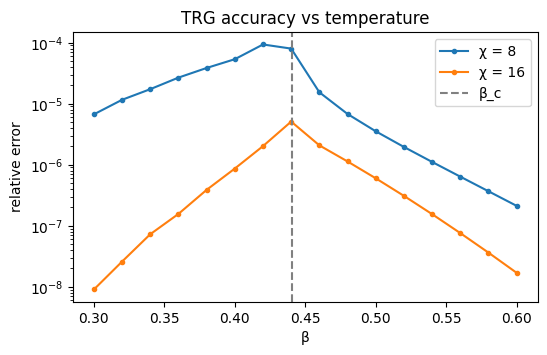

In [16]:
betas = np.linspace(0.3, 0.6, 16)
fig, ax = plt.subplots(figsize=(6, 3.5))
for chi in (8, 16):
    err = [abs(trg_free_energy(b, chi, 30) - f_exact(b)) / abs(f_exact(b)) for b in betas]
    ax.semilogy(betas, err, "o-", ms=3, label=f"χ = {chi}")
ax.axvline(beta_c, color="gray", ls="--", label="β_c")
ax.set(xlabel="β", ylabel="relative error", title="TRG accuracy vs temperature")
ax.legend()
plt.show()

The error **peaks at $\beta_c$**. There the correlation length diverges, the system is scale invariant and every RG step
has to carry entanglement from all length scales; a fixed χ cannot. Away from $\beta_c$ the tensor flows quickly
to a trivial (low-rank) fixed point and TRG is almost exact. Fixing this at criticality is what improved
schemes such as BTRG, HOTRG and LoopTNR are for — see the treasure chest. 🦜

#### (c) Specific heat

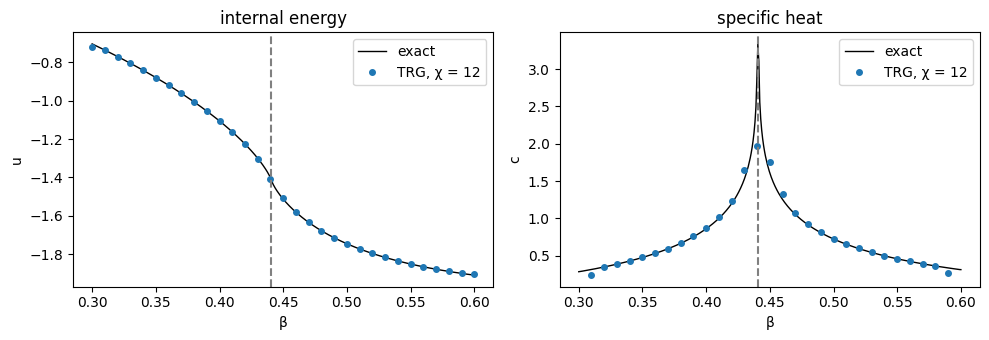

In [17]:
betas = np.linspace(0.3, 0.6, 31)
bf = np.array([b * trg_free_energy(b, 12, 30) for b in betas])
u = np.gradient(bf, betas)
c = -betas**2 * np.gradient(u, betas)

fine = np.linspace(0.3, 0.6, 400) + 1e-7     # avoid hitting β_c exactly
u_ex = u_exact(fine)
c_ex = -fine**2 * np.gradient(u_ex, fine)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(fine, u_ex, "k-", lw=1, label="exact")
ax[0].plot(betas, u, "o", ms=4, label="TRG, χ = 12")
ax[0].set(xlabel="β", ylabel="u", title="internal energy")
ax[1].plot(fine, c_ex, "k-", lw=1, label="exact")
ax[1].plot(betas[1:-1], c[1:-1], "o", ms=4, label="TRG, χ = 12")  # drop one-sided edge points
ax[1].set(xlabel="β", ylabel="c", title="specific heat")
for a in ax:
    a.axvline(beta_c, color="gray", ls="--")
    a.legend()
plt.tight_layout()
plt.show()

The TRG points follow the exact $u(\beta)$ (with its infinite slope at $\beta_c$) and the specific heat shows the logarithmic peak, smeared by the finite grid and finite χ.

---
## 🦜 7 · The real treasure: **TNRKit.jl**

You opened the vault and inside there is... a Julia package. Arrr. Hear the parrot out.

> *"Squawk! Ye spent an hour writing 40 lines of TRG. Me captain does it in three!"*

```julia
using TNRKit, TensorKit

T    = classical_ising(ising_βc)                    # the tensor from Ising Isle (ℤ₂-symmetric)
data = run!(BTRG(T), truncrank(16), maxiter(25))    # bond-weighted TRG, χ = 16
f    = free_energy(data, ising_βc)                  # -2.109650492614   (rel. error 3.1e-7)
```

**[TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl)** is a Julia package that implements tensor network
renormalization the way you just did — same leg convention `(l, d, u, r)`, same normalise-and-sum free energy —
but with dozens of models, a whole arsenal of algorithms, and the physics extraction already built in. Built on
[TensorKit.jl](https://github.com/Jutho/TensorKit.jl), so symmetries (ℤ₂, ℤ_N, U(1), fermions, ...) come for free.

### 🗝️ Everything you built today is in there
| Today, in numpy | In TNRKit.jl |
|---|---|
| `ising_tensor(β)` | `classical_ising(Trivial, β)` — *identical, entry by entry* |
| `split_tensor(T, χ)` | `SVD12(T, truncrank(χ))` |
| `trg_step(T, χ)` | `step!(TRG(T), truncrank(χ))` |
| the loop over steps | `run!(scheme, truncrank(χ), maxiter(n))` |
| `Σ ln(n_k)/2^k` | `free_energy(data, β)` |
| `f_exact(β)` | `f_onsager` |

Your χ = 16 TRG and `run!(TRG(T), truncrank(16), maxiter(30))` give **the same free energy to all 12 printed digits**
(−2.109641375532 at β_c).

### ⚔️ The arsenal — algorithms
Same model, same χ = 16, at the critical point (relative error of the free energy):

| scheme | idea | rel. error at β_c |
|---|---|---|
| `TRG` | what you wrote today | 3.9e-6 |
| `BTRG` | TRG + bond weights — same cost | **3.2e-7** |
| `HOTRG` | higher-order SVD, isometries | 5.6e-7 |
| `ATRG` | anisotropic TRG (built for 3D) | 3.4e-6 |
| `LoopTNR` | entanglement filtering + loop optimisation — the CFT machine | 5.3e-6 |

…and also `SLoopTNR`, the CTM family (`CTM`, `c4vCTM`, `rCTM`, `ctm_TRG`, `ctm_HOTRG`, triangular & honeycomb CTMs),
`ImpurityTRG`, `ImpurityHOTRG`, `CorrelationHOTRG`, and in **3D** `HOTRG_3D`, `ATRG_3D` and `ThermalTNR`.
Switching algorithm = changing **one word**.

### 🐙 The model zoo
| call | model |
|---|---|
| `classical_ising(β; Jx, Jy, h)` | 2D Ising (also anisotropic, in a field, triangular, honeycomb) |
| `classical_ising_3D(β)` | 3D Ising |
| `classical_potts(q, β)` | $q$-state Potts |
| `classical_clock(q, β)` | $q$-state clock (BKT physics!) |
| `classical_XY(U1Irrep, β, charge_trunc)` | XY model |
| `sixvertex(; a, b, c)` | six-vertex model |
| `phi4_real`, `phi4_complex` | lattice $\phi^4$ field theory |
| `gross_neveu_start(μ, m, g)` | Gross–Neveu — fermions at finite density, no sign problem |

Bring your own model? Just respect the `(l, d, u, r)` leg convention — which you now know by heart.

### 🔭 Physics, not just free energies

**Magnetisation** (with a tiny field to pick a ground state), compared with Yang's exact result:
```julia
β, h = 0.5, 1e-8
Tp   = classical_ising(Trivial, β; h)               # pure tensor
Ti   = classical_ising_impurity(β; h)               # same tensor with a σ inserted
data = run!(ImpurityHOTRG(Tp, Ti, Ti, Tp), truncrank(16), maxiter(25))
m    = data[end][2] / data[end][1]                  # 0.911301   (Yang: 0.911319)
```

**CFT data** — central charge and scaling dimensions, straight from the fixed-point tensor:
```julia
scheme = LoopTNR(classical_ising(ising_βc))
run!(scheme, truncrank(16), maxiter(15))
cft = CFTData(scheme)
cft.central_charge                                  # 0.5000008      (exact: 1/2)
sort(real.(parent(cft.scaling_dimensions)))[1:10]
# 0.0  0.125  1.0  1.125  1.125  2.0001  2.0005  2.0006  2.0006  2.125
# exact: 0, 1/8, 1, 9/8, 9/8, 2, 2, 2, 2, 17/8   (σ, ε, descendants...)
```

**Which phase am I in?** Count the ground states from the fixed-point tensor:
```julia
for β in (0.9 * ising_βc, 1.1 * ising_βc)
    scheme = BTRG(classical_ising(β))
    run!(scheme, truncrank(16), maxiter(25))
    println(ground_state_degeneracy(scheme))        # 1.0 -> disordered,  2.0 -> ordered (ℤ₂ broken)
end
```

### 🏝️ Take it home
* ⭐ GitHub: <https://github.com/QuantumKitHub/TNRKit.jl> — docs: <https://quantumkithub.github.io/TNRKit.jl/stable/>
* Install: in Julia, `] add TNRKit TensorKit`.
* No Julia? Colab has a native Julia runtime: *Runtime → Change runtime type → Julia*, then
  `using Pkg; Pkg.add(["TNRKit", "TensorKit"])` (the first `using TNRKit` compiles for a few minutes — grab a grog 🍹).
* Questions, ideas, a model you'd like to see? Open an issue or a discussion on GitHub. PRs are very welcome.

> *"The real treasure was the tensors we contracted along the way."* — the parrot 🦜